# Chapitre 3 - Cours 3 : Similarité sémantique, embeddings et IA comme juge

Ce notebook couvre la fin de la section *Exact Evaluation* (sous-sections *Semantic
similarity* et *Introduction to Embedding*) puis la section *AI as a Judge* en entier :
pourquoi et comment utiliser une IA comme juge, ses limites (incohérence, ambiguïté des
critères, coût et latence, biais) et le choix du modèle juge.

**Plan.**

1. Similarité sémantique : quand la forme et le sens divergent.
2. Introduction aux embeddings : vecteurs, similarité cosinus, projection 2D, espaces
   multimodaux.
3. L'IA comme juge : principe, grille de notation, juge « probabiliste ».
4. Quel modèle peut juger ? Qwen 0,5 B contre 1,5 B face à des notes humaines.
5. Biais de position.
6. Biais de verbosité.
7. Incohérence et ambiguïté des critères.
8. Coût et latence d'un juge.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.decomposition import PCA

from aie import ch03_evaluation as ev
from aie import llm
from aie.diagrams import Diagram
from aie.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                          annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
llm.seed_everything(0)
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 60)

## 1. Similarité sémantique (section *Semantic similarity*)

**Motivation.** La similarité lexicale compare la **forme**. Or deux textes peuvent dire
la même chose avec des mots différents (« What's up? » et « How are you? ») ou des
choses opposées avec presque les mêmes mots (« Let's eat, grandma » et « Let's eat
grandma », exemple du livre). La similarité sémantique compare le **sens** : on
transforme chaque texte en un vecteur, son **embedding**, puis on mesure l'angle entre
vecteurs par la **similarité cosinus**
$$\cos(A, B) = \frac{A\cdot B}{\|A\|\,\|B\|} \in [-1, 1],$$
qui vaut 1 pour deux vecteurs de même direction et $-1$ pour deux vecteurs opposés. Si
les embeddings sont normalisés ($\|A\| = \|B\| = 1$), c'est un simple produit scalaire,
et $\|A - B\|^2 = 2 - 2\cos(A, B)$ : cosinus et distance euclidienne donnent alors le même
classement.

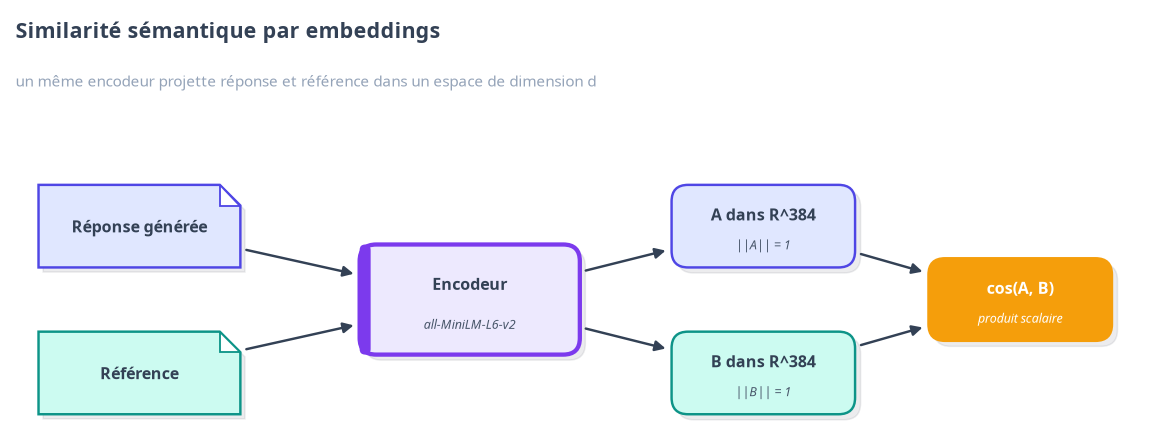

In [2]:
d = Diagram(12.5, 3.6, title="Similarité sémantique par embeddings",
            subtitle="un même encodeur projette réponse et référence dans un espace de dimension d")
d.box("gen", 1.4, 2.2, "Réponse générée", color=INDIGO, kind="doc", w=2.2, h=0.9)
d.box("ref", 1.4, 0.6, "Référence", color=TEAL, kind="doc", w=2.2, h=0.9)
d.box("enc", 5.0, 1.4, "Encodeur", sub="all-MiniLM-L6-v2", color=VIOLET, kind="model", w=2.4, h=1.2)
d.box("a", 8.2, 2.2, "A dans R^384", sub="||A|| = 1", color=INDIGO, w=2.0)
d.box("b", 8.2, 0.6, "B dans R^384", sub="||B|| = 1", color=TEAL, w=2.0)
d.box("cos", 11.0, 1.4, "cos(A, B)", sub="produit scalaire", color=AMBER, w=2.0, filled=True)
d.arrow("gen", "enc"); d.arrow("ref", "enc"); d.arrow("enc", "a"); d.arrow("enc", "b")
d.arrow("a", "cos"); d.arrow("b", "cos")
d.show()

Comparons les métriques lexicales du cours 2 et la similarité cosinus (modèle
`all-MiniLM-L6-v2`, 384 dimensions) sur des paires choisies pour piéger l'une ou
l'autre.

In [3]:
paires = [
    ("What's up?", "How are you?", "même sens, mots différents"),
    ("The movie was fantastic.", "I really loved this film.", "même sens, mots différents"),
    ("The cat sat on the mat.", "On the mat sat the cat.", "même sens, ordre changé"),
    ("Let's eat, grandma.", "Let's eat grandma.", "sens opposé, forme quasi identique"),
    ("The test passed.", "The test did not pass.", "négation"),
    ("Paris is the capital of France.", "Berlin is the capital of France.", "fait faux, forme identique"),
    ("The stock market fell sharply today.", "My grandmother bakes delicious bread.", "sans rapport"),
]
E1 = llm.embed([a for a, _, _ in paires])
E2 = llm.embed([b for _, b, _ in paires])
sim = pd.DataFrame([dict(paire=f"{a} | {b}", situation=s, edition=ev.edit_similarity(a.lower(), b.lower()),
                         bleu=ev.bleu(a, b), rouge_l=ev.rouge_l(a, b)["f1"], cosinus=float(e1 @ e2))
                    for (a, b, s), e1, e2 in zip(paires, E1, E2)])
sim

,paire,situation,edition,bleu,rouge_l,cosinus
0,What's up? | How are you?,"même sens, mots différents",0.250,0.000,0.000,0.425
1,The movie was fantastic. | I really loved this film.,"même sens, mots différents",0.160,0.000,0.000,0.709
2,The cat sat on the mat. | On the mat sat the cat.,"même sens, ordre changé",0.652,0.508,0.500,0.894
3,"Let's eat, grandma. | Let's eat grandma.","sens opposé, forme quasi identique",0.947,1.000,1.000,0.958
4,The test passed. | The test did not pass.,négation,0.545,0.296,0.500,0.744
5,Paris is the capital of France. | Berlin is the capital ...,"fait faux, forme identique",0.875,0.803,0.833,0.717
6,The stock market fell sharply today. | My grandmother ba...,sans rapport,0.189,0.000,0.000,0.017


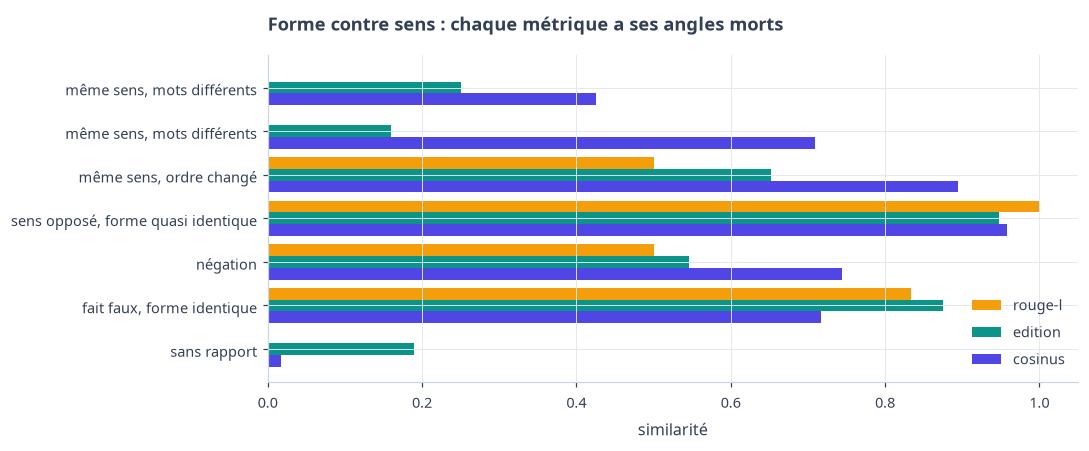

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(sim))
for k, (col, c) in enumerate([("rouge_l", AMBER), ("edition", TEAL), ("cosinus", INDIGO)]):
    ax.barh(y + (k - 1) * 0.27, sim[col], height=0.27, color=c, label=col.replace("_", "-"))
ax.set_yticks(y); ax.set_yticklabels(sim.situation); ax.invert_yaxis()
ax.set_xlabel("similarité"); ax.set_xlim(0, 1.05)
ax.set_title("Forme contre sens : chaque métrique a ses angles morts")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

Les embeddings reconnaissent les paraphrases (« What's up? » / « How are you? ») là où
ROUGE-L et la distance d'édition échouent. Mais ils ont leurs propres angles morts : une
négation ou un fait faux (« Berlin is the capital of France ») gardent un cosinus élevé,
car le **sujet** est le même. La similarité sémantique mesure la proximité thématique
plus que la vérité. Le livre note aussi qu'elle dépend entièrement de la qualité de
l'encodeur (c'est pourquoi on peut la considérer comme partiellement subjective) et
qu'elle coûte un passage dans un réseau de neurones. Des métriques comme BERTScore
raffinent l'idée en alignant les embeddings **token par token**.

> **À retenir.** La similarité sémantique compare des embeddings par le cosinus. Elle
> tolère les paraphrases, demande moins de références que les métriques lexicales, mais
> reste aveugle à la négation et aux erreurs factuelles qui ne changent pas le sujet.

## 2. Introduction aux embeddings (section *Introduction to Embedding*)

Un **embedding** est une représentation vectorielle qui cherche à capturer le sens d'une
donnée. Les tailles typiques vont de quelques centaines à quelques milliers de
composantes (384 pour notre modèle, 768 pour BERT-base, 1 536 ou 3 072 pour les modèles
d'embeddings d'OpenAI d'après le tableau 3-2), bien moins que la dimension des données
brutes. Comment vérifier qu'un embedding « capture le sens » ? Le critère du livre :
des textes plus similaires doivent avoir des embeddings plus proches. Testons-le sur 24
phrases de quatre thèmes, dont les trois phrases du livre.

In [5]:
corpus = {
    "animaux": ["the cat sits on a mat", "the dog plays on the grass", "a horse runs across the field",
                "birds are singing in the trees", "my rabbit eats carrots every morning", "the puppy chased its tail"],
    "cuisine": ["she baked a chocolate cake for dessert", "add salt and pepper to the soup",
                "this restaurant serves excellent pasta", "slice the onions before frying them",
                "fresh bread smells wonderful", "he grilled vegetables for dinner"],
    "IA": ["AI research is super fun", "the neural network was trained on GPUs",
           "large language models predict the next token", "we evaluated the model on a benchmark",
           "embeddings map sentences to vectors", "the transformer uses attention layers"],
    "sport": ["the striker scored a goal in the final minute", "she won the tennis match in three sets",
              "the marathon starts at eight", "our team lost the basketball game",
              "he trains at the swimming pool daily", "the cyclist climbed the mountain stage"],
}
phrases = [p for v in corpus.values() for p in v]
themes = [t for t, v in corpus.items() for _ in v]
E = llm.embed(phrases)
print("dimension :", E.shape[1], " | normes :", np.round(np.linalg.norm(E, axis=1)[:3], 3))
S = E @ E.T
book = pd.Series({"« the dog plays on the grass »": S[0, 1], "« AI research is super fun »": S[0, 12]},
                 name="cosinus avec « the cat sits on a mat »")
book.to_frame()

dimension : 384  | normes : [1. 1. 1.]


,cosinus avec « the cat sits on a mat »
« the dog plays on the grass »,0.272
« AI research is super fun »,-0.050


Le critère du livre est vérifié : « the cat sits on a mat » est plus proche de « the dog
plays on the grass » que de « AI research is super fun ». La matrice complète et une
projection en deux dimensions (analyse en composantes principales, qui conserve les
directions de plus grande variance) montrent la structure par thèmes.

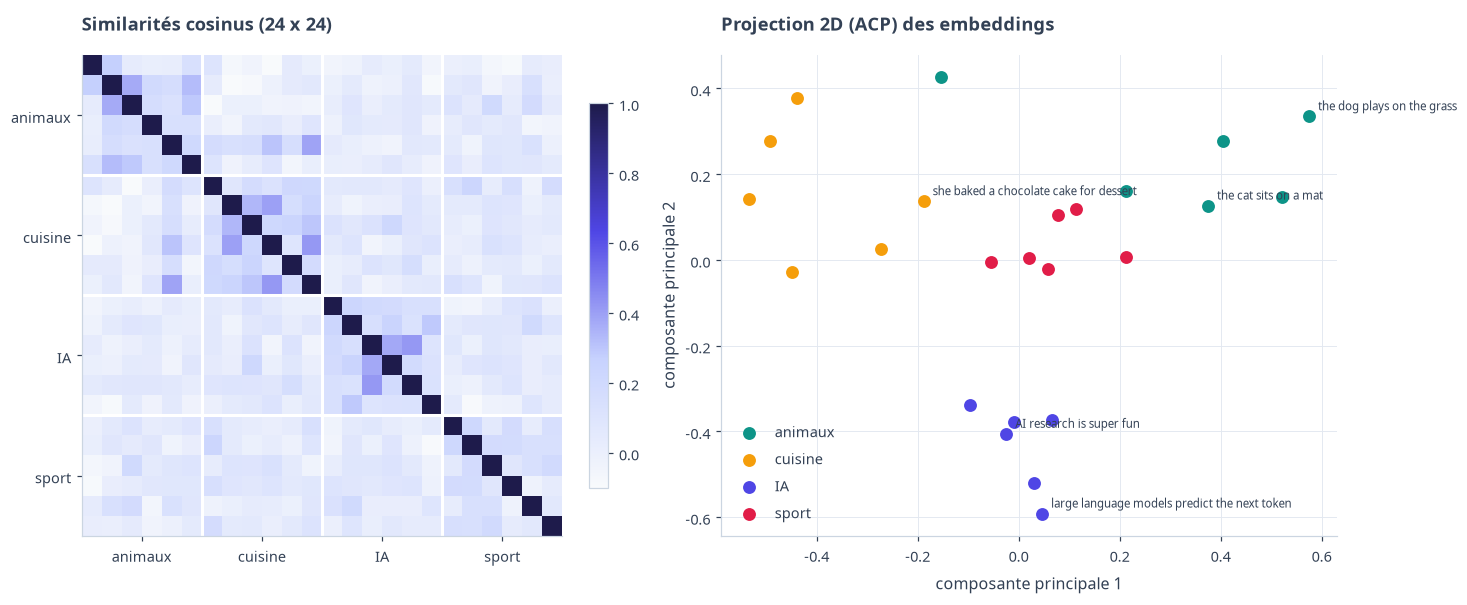

In [6]:
couleur = {"animaux": TEAL, "cuisine": AMBER, "IA": INDIGO, "sport": ROSE}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.6), gridspec_kw=dict(width_ratios=[1, 1.15]))
im = ax1.imshow(S, cmap="aie_seq", vmin=-0.1, vmax=1)
for k in range(1, 4):
    ax1.axhline(6 * k - 0.5, color="white", lw=2); ax1.axvline(6 * k - 0.5, color="white", lw=2)
ax1.set_xticks([2.5, 8.5, 14.5, 20.5]); ax1.set_xticklabels(corpus.keys())
ax1.set_yticks([2.5, 8.5, 14.5, 20.5]); ax1.set_yticklabels(corpus.keys())
ax1.grid(False); ax1.set_title("Similarités cosinus (24 x 24)")
plt.colorbar(im, ax=ax1, fraction=0.046, shrink=0.8)
Z = PCA(n_components=2, random_state=0).fit_transform(E)
for t in corpus:
    idx = [i for i, x in enumerate(themes) if x == t]
    ax2.scatter(Z[idx, 0], Z[idx, 1], color=couleur[t], s=55, label=t, zorder=3)
for i in [0, 1, 12, 6, 14]:
    ax2.annotate(phrases[i], Z[i], (6, 4), textcoords="offset points", fontsize=7.5, color=SLATE)
ax2.set_xlabel("composante principale 1"); ax2.set_ylabel("composante principale 2")
ax2.set_title("Projection 2D (ACP) des embeddings")
ax2.legend(loc="best")
finish(fig)
plt.show()

Les blocs diagonaux (même thème) sont nettement plus clairs : les phrases d'un même
thème sont proches. Remarquez deux propriétés pratiques :

- les similarités entre thèmes différents ne sont pas centrées sur 0 mais légèrement
  positives : un cosinus « élevé » n'a de sens que relativement à une distribution de
  référence, d'où l'intérêt de calibrer un seuil sur ses propres données ;
- la projection 2D ne conserve qu'une partie de l'information (la variance expliquée est
  faible en dimension 384) : elle illustre, elle ne mesure pas.

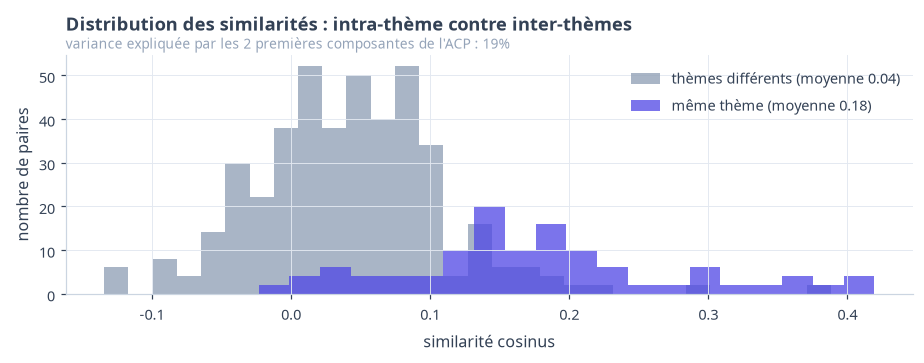

In [7]:
intra = S[np.equal.outer(themes, themes) & ~np.eye(24, dtype=bool)]
inter = S[~np.equal.outer(themes, themes)]
fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.hist(inter, bins=30, color=GRAY, alpha=0.8, label=f"thèmes différents (moyenne {inter.mean():.2f})")
ax.hist(intra, bins=20, color=INDIGO, alpha=0.75, label=f"même thème (moyenne {intra.mean():.2f})")
ax.set_xlabel("similarité cosinus"); ax.set_ylabel("nombre de paires")
ax.set_title("Distribution des similarités : intra-thème contre inter-thèmes")
subtitle(ax, f"variance expliquée par les 2 premières composantes de l'ACP : "
             f"{PCA(2).fit(E).explained_variance_ratio_.sum():.0%}")
ax.legend()
plt.tight_layout(); plt.show()

**Usages.** Le livre rappelle que la similarité sert bien au-delà de l'évaluation :
recherche (chapitre 6), classement, regroupement, détection d'anomalies, déduplication
(chapitre 8). Une requête de recherche sémantique en une ligne :

In [8]:
requete = "which sentence talks about machine learning hardware?"
scores = E @ llm.embed(requete)[0]
pd.DataFrame({"phrase": np.array(phrases)[np.argsort(-scores)[:3]], "cosinus": np.sort(scores)[::-1][:3]})

,phrase,cosinus
0,the neural network was trained on GPUs,0.437
1,embeddings map sentences to vectors,0.304
2,AI research is super fun,0.280


**Embeddings multimodaux.** CLIP (Radford et al., 2021) apprend un **espace joint** pour
le texte et l'image à partir de paires (image, légende) : un encodeur par modalité, une
projection vers un espace commun, et un objectif **contrastif** qui rapproche
l'embedding d'une image de celui de sa légende et l'éloigne des autres légendes du lot.
On peut alors chercher des images avec du texte. ULIP et ImageBind étendent l'idée à la
3D, à l'audio et à d'autres modalités.

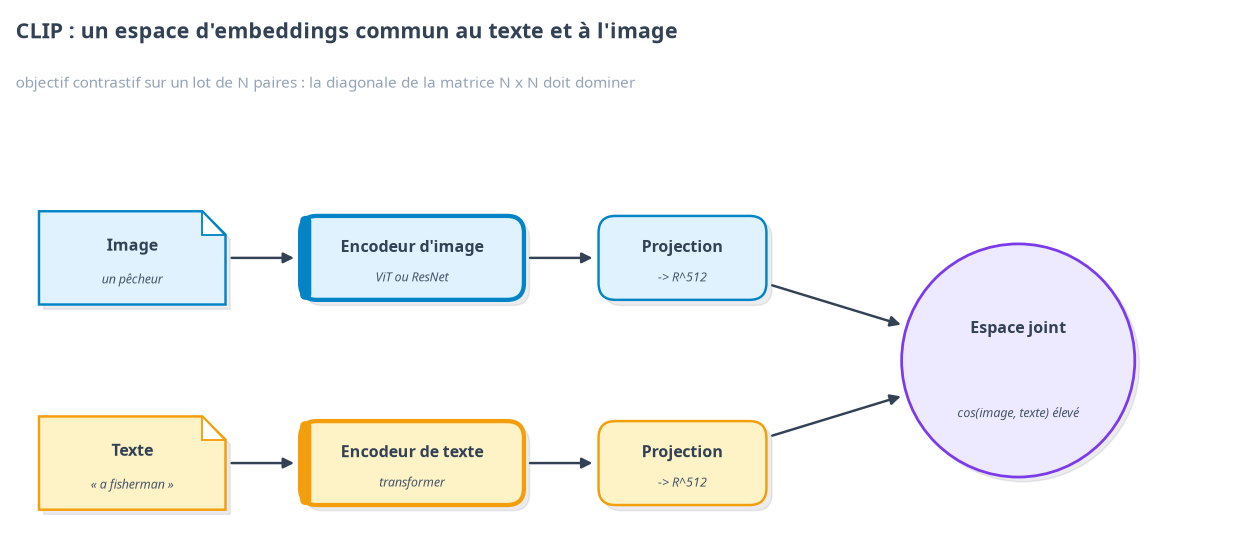

In [9]:
d = Diagram(13, 4.8, title="CLIP : un espace d'embeddings commun au texte et à l'image",
            subtitle="objectif contrastif sur un lot de N paires : la diagonale de la matrice N x N doit dominer")
d.box("img", 1.3, 3.1, "Image", sub="un pêcheur", color=SKY, kind="doc", w=2.0, h=1.0)
d.box("txt", 1.3, 0.9, "Texte", sub="« a fisherman »", color=AMBER, kind="doc", w=2.0, h=1.0)
d.box("ei", 4.3, 3.1, "Encodeur d'image", sub="ViT ou ResNet", color=SKY, kind="model", w=2.4)
d.box("et", 4.3, 0.9, "Encodeur de texte", sub="transformer", color=AMBER, kind="model", w=2.4)
d.box("pi", 7.2, 3.1, "Projection", sub="-> R^512", color=SKY, w=1.8)
d.box("pt", 7.2, 0.9, "Projection", sub="-> R^512", color=AMBER, w=1.8)
d.box("space", 10.8, 2.0, "Espace joint", sub="cos(image, texte) élevé", color=VIOLET, kind="circle", w=2.5)
d.arrow("img", "ei"); d.arrow("txt", "et"); d.arrow("ei", "pi"); d.arrow("et", "pt")
d.arrow("pi", "space"); d.arrow("pt", "space")
d.show()

> **À retenir.** Un embedding est un vecteur de quelques centaines à quelques milliers de
> dimensions ; un bon encodeur rapproche les données de sens voisin, ce qu'on vérifie
> par la similarité cosinus ou sur des benchmarks comme MTEB. Les embeddings sont au cœur
> de la recherche, du RAG et de la déduplication, et peuvent être multimodaux (CLIP).

## 3. L'IA comme juge : principe et grille (sections *AI as a Judge*, *Why AI as a Judge?*, *How to Use AI as a Judge*)

**Motivation.** Les réponses ouvertes résistent aux métriques exactes et l'évaluation
humaine est lente et chère. Idée : demander à un modèle d'évaluer les sorties d'un
autre. Les juges IA sont rapides, bon marché, flexibles (n'importe quel critère :
justesse, toxicité, fidélité au contexte...) et peuvent se passer de référence, donc
fonctionner en production. Le livre cite des accords juge-humain de l'ordre de 85 %
(GPT-4 sur MT-Bench), supérieurs à l'accord entre humains.

Trois usages, illustrés par les prompts naïfs du livre :

1. **ponctuel** : noter une réponse seule (par exemple de 1 à 5) ;
2. **avec référence** : dire si la réponse équivaut à une réponse de référence ;
3. **par paires** : désigner la meilleure de deux réponses (utile pour les données de
   préférence et le classement comparatif du cours 4).

Un prompt de juge doit préciser la **tâche**, les **critères** et le **système de
notation** (classes, notes discrètes, ou valeurs continues : les modèles réussissent
mieux avec des classes ou une petite échelle discrète, typiquement 1 à 5). Surtout : un
juge n'est pas un modèle mais un **système** modèle + prompt + paramètres
d'échantillonnage ; changer l'un des trois change le juge.

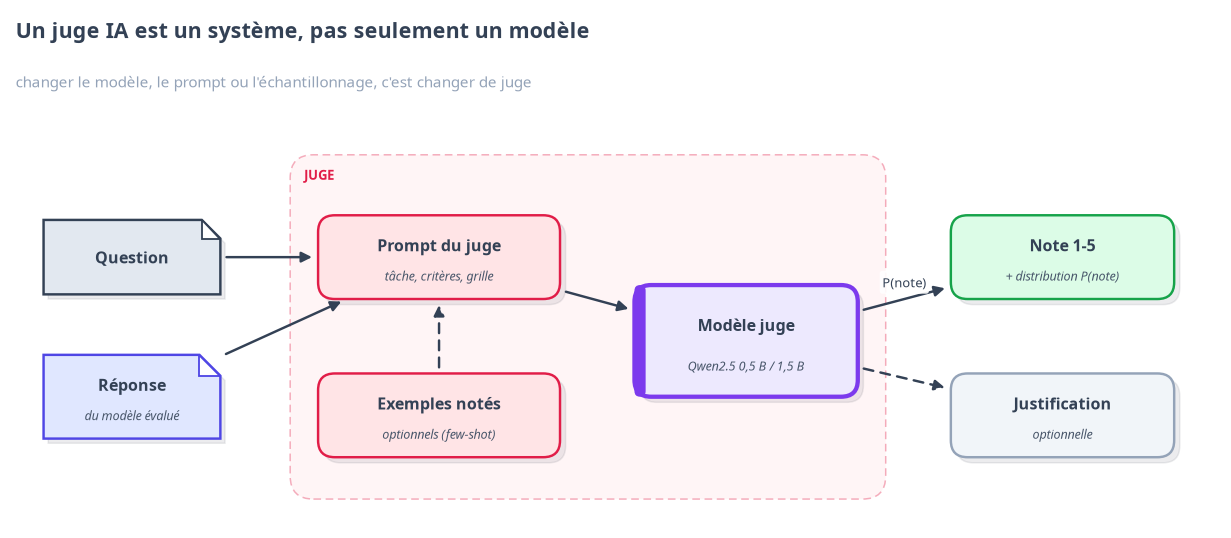

In [10]:
d = Diagram(13, 4.6, title="Un juge IA est un système, pas seulement un modèle",
            subtitle="changer le modèle, le prompt ou l'échantillonnage, c'est changer de juge")
d.group(3.0, 0.3, 9.4, 4.0, "juge", ROSE)
d.box("q", 1.3, 2.9, "Question", color=SLATE, kind="doc", w=1.9, h=0.8)
d.box("r", 1.3, 1.4, "Réponse", sub="du modèle évalué", color=INDIGO, kind="doc", w=1.9, h=0.9)
d.box("p", 4.6, 2.9, "Prompt du juge", sub="tâche, critères, grille", color=ROSE, w=2.6)
d.box("ex", 4.6, 1.2, "Exemples notés", sub="optionnels (few-shot)", color=ROSE, w=2.6)
d.box("m", 7.9, 2.0, "Modèle juge", sub="Qwen2.5 0,5 B / 1,5 B", color=VIOLET, kind="model", w=2.4, h=1.2)
d.box("s", 11.3, 2.9, "Note 1-5", sub="+ distribution P(note)", color=GREEN, w=2.4)
d.box("e", 11.3, 1.2, "Justification", sub="optionnelle", color=GRAY, w=2.4)
d.arrow("q", "p"); d.arrow("r", "p"); d.arrow("ex", "p", style="dashed"); d.arrow("p", "m")
d.arrow("m", "s", "P(note)"); d.arrow("m", "e", style="dashed")
d.show()

**Notre juge.** Grille de 1 à 5 (`ev.RUBRIC_1_5`), modèles Qwen2.5-Instruct. Plutôt que
de générer un texte puis de le parser, on lit en une seule passe avant la
**distribution** du premier token de réponse sur les cinq chiffres, après le préfixe
« Score: ». On en déduit la note la plus probable et la **note attendue**
$\mathbb E[s] = \sum_s s\,P(s)$, plus fine et plus stable qu'une note tirée au sort
(c'est l'idée de G-Eval). Voici le prompt complet pour une réponse :

In [11]:
print(ev.RUBRIC_1_5 + "\n\nQUESTION: What is the capital of Australia?\nANSWER: The capital of Australia is Sydney.")

You are a strict grader. Rate the ANSWER to the QUESTION for factual correctness and helpfulness.
Scoring rubric:
1 = wrong or irrelevant answer.
2 = mostly wrong, with a small correct element.
3 = partially correct or incomplete.
4 = correct but with a minor flaw.
5 = fully correct, clear and complete.
Reply with a single digit from 1 to 5.

QUESTION: What is the capital of Australia?
ANSWER: The capital of Australia is Sydney.


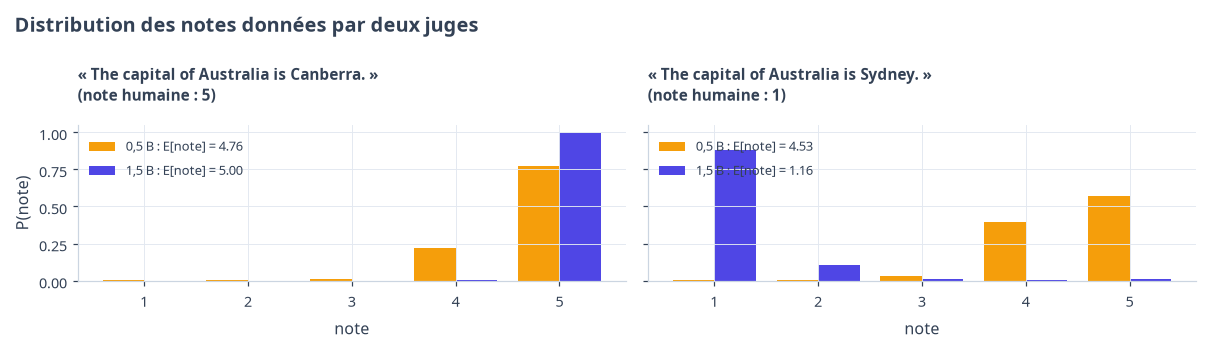

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, (q, a, h) in zip(axes, [ev.JUDGE_QA[0], ev.JUDGE_QA[1]]):
    for mid, c, dx in [(llm.SMALL, AMBER, -0.2), (llm.MEDIUM, INDIGO, 0.2)]:
        j = ev.judge_pointwise(q, a, mid)
        ax.bar(np.arange(1, 6) + dx, [j["probs"][str(s)] for s in range(1, 6)], width=0.4, color=c,
               label=f"{'0,5 B' if mid == llm.SMALL else '1,5 B'} : E[note] = {j['score']:.2f}")
    ax.set_title(f"« {a} »\n(note humaine : {h})", fontsize=10)
    ax.set_xlabel("note"); ax.legend(fontsize=8.5, loc="upper left")
axes[0].set_ylabel("P(note)")
finish(fig, "Distribution des notes données par deux juges")
plt.show()

> **À retenir.** Un juge IA se définit par son modèle, son prompt (tâche, critères,
> grille, exemples) et son échantillonnage. Lire la distribution des notes plutôt
> qu'une note générée donne un score continu, déterministe et peu coûteux.